In [1]:
!pip install langchain langgraph

In [2]:
!pip install -qU langchain-groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 5.0 MB/s eta 0:00:00


In [3]:
!pip install langchain-tavily

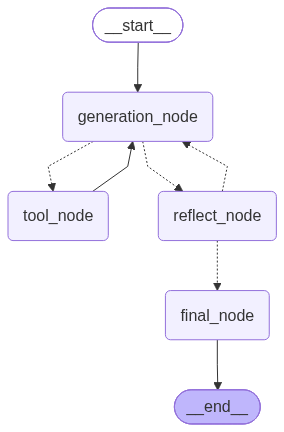

JOB POSTING
AI Engineer
Virtualyyst
Mumbai, Maharashtra, India
https://in.linkedin.com/jobs/view/ai-engineer-2%2Byrs-exp-at-virtualyyst-4476667554
Build AI‑powered solutions, integrate AI models and services via APIs, work with LLMs and vision APIs, support development, testing and implementation of AI applications, collaborate with engineering teams, troubleshoot AI tool issues. Immediate joiners only.
JOB POSTING
Data Engineer
Visa
Bengaluru, Karnataka, India
https://in.linkedin.com/jobs/view/data-engineer-1-2-years-of-experience-in-java-python-go-kafka-flink-hadoop-at-visa-4468605507
Develop and maintain large‑scale data pipelines for payment‑processing analytics using Java, Python, Go, Kafka, Flink, Hadoop and cloud platforms. Participate in Visa’s AI‑enabled fraud detection initiatives.
JOB POSTING
Data Engineer
Natlov Technologies Pvt Ltd
Delhi, India (Remote, Night Shift)
https://in.linkedin.com/jobs/view/data-engineer-at-natlov-technologies-pvt-ltd-4477971644
Design, build, and

In [16]:
from typing import List,Annotated,TypedDict,Literal
from pydantic import BaseModel,Field
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, SystemMessage,AIMessage
from langchain_tavily import TavilySearch
from langchain_core.tools import tool

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode

from IPython.display import Image, display
import os

class Job(BaseModel):
  title:str = Field(description='Title of the job posting')
  keywords:List[str] = Field(default_factory=list, description='Keywords related to the job posting')
  company:str = Field(description='Name of the company')
  location:str = Field(description='Location of the job posting')
  url:str = Field(description='URL of the job posting')
  description:str = Field(description='Description of the job posting')

class JobPostings(BaseModel):
  jobs:List[Job] = Field(description='List of job postings')

class ReflectionLLMResponse(BaseModel):
  decision:Literal['continue','stop'] = Field(description='Decision to continue or stop generation')
  reflection:str = Field(description='Reflection on the decision')

class State(TypedDict):
  messages:Annotated[list,add_messages]
  jobs:List[Job]
  decision:Literal['continue','stop']
  reflection:str
  reflection_count:int


os.environ['GROQ_API_KEY'] = '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'
os.environ['TAVILY_API_KEY'] = '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'



"""
messages = [
    (
        "system",
        "You are a helpful assistant that translates English to French. Translate the user sentence.",
    ),
    ("human", "I love programming."),
]
ai_msg = llm.invoke(messages)
print(ai_msg.content)
"""

@tool
def add(a:float,b:float)->float:
  """
  Args :- a = number to be added
          b = number to be added
  Returns :- Sum of the two numbers
  """
  return a+b

@tool
def subtract(a:float,b:float)->float:
  """
  Args :- a = number to be subtracted
          b = number to be subtracted
  Returns :- Absolute sum of the two numbers
  """
  return abs(a+b)

search = TavilySearch(max_results=2)

tools = [add,subtract,search]

llm = ChatGroq(model = 'openai/gpt-oss-120b')
llm_with_tools = llm.bind_tools(tools)
llm_for_reflection = llm.with_structured_output(ReflectionLLMResponse)
llm_final_answer = llm.with_structured_output(JobPostings)

def generation_node(state:State):
  response = llm_with_tools.invoke(state['messages'])

  return {'messages':[response]}

tool_node = ToolNode(tools)

def should_go_to_reflection(state:State):
  last_mssg = state['messages'][-1]

  if last_mssg.tool_calls:
    return 'tool_node'
  return 'reflect_node'

def reflect_node(state:State):
    response = llm_for_reflection.invoke(
        state['messages'] + [HumanMessage(content=
            "Do NOT answer the user. Evaluate the conversation above: have enough job "
            "postings been gathered? Return decision ('continue' or 'stop') and a brief reflection.")]
    )
    reflection_count = state['reflection_count']
    return {'decision':response.decision,'reflection':response.reflection,
            'messages':[AIMessage(content=response.reflection)],'reflection_count':reflection_count+1}


def should_go_to_generation(state:State):
  if state['decision'] == 'continue' and state['reflection_count'] <= 1:
    return 'generation_node'
  else:
    return 'final_node'

def final_node(state:State):
    response = llm_final_answer.invoke(
        state['messages'] + [HumanMessage(content=
            "Extract every job posting mentioned above into the structured schema.")]
    )
    return {'jobs':response.jobs}

graph = StateGraph(State)

graph.add_node('generation_node',generation_node)
graph.add_node('tool_node',tool_node)
graph.add_node('reflect_node',reflect_node)
graph.add_node('final_node',final_node)

graph.add_edge(START,'generation_node')
graph.add_conditional_edges(
    'generation_node',
    should_go_to_reflection,
    {
        'tool_node':'tool_node',
        'reflect_node':'reflect_node'
    }
)

graph.add_edge('tool_node','generation_node')

graph.add_conditional_edges(
    'reflect_node',
    should_go_to_generation,
    {
        'generation_node':'generation_node',
        'final_node':'final_node'
    }
)

graph.add_edge('final_node',END)

app = graph.compile()

png_bytes = app.get_graph().draw_mermaid_png()

display(Image(png_bytes))

res = app.invoke(
    {
        'messages':[
            SystemMessage(content='You are Multi purpose Agent. You have a set of tools that you can use.'),
            HumanMessage(content='Find me 5 job postings on AI Engineering, Data Engineering, Data Scientist, ML Engineering, etc in India, I have 2 years of experience.')
        ],
        'jobs':[],
        'decision':'continue',
        'reflection':'',
        'reflection_count':0
    }
)

for job in res['jobs']:
  print("JOB POSTING")
  print(job.title)
  print(job.company)
  print(job.location)
  print(job.url)
  print(job.description)


